# Predicting the parameter bias from a wrong n(z)

`FisherFlex.forecast` says how *precisely* a survey measures cosmology.  This notebook
uses `FisherFlex.forecast_bias` to ask the other question: if the true source n(z) is not
the one we assumed, how far off is the answer?

It uses the DESC nz-challenge task-set 1 (Cardinal, 1yr, WFD) files in this directory,
where the *truth* is known -- so we can measure the bias rather than guess at it.

In [1]:
import numpy as np
from matplotlib import pyplot as plt

# Recarga los módulos locales cuando se vuelve a ejecutar esta celda.
import importlib
import inspect
import fisherA2Z.fisher_flex as ff
importlib.reload(ff.nzq)
ff = importlib.reload(ff)
FisherFlex = ff.FisherFlex
print("Fisher:", ff.__file__)
print("Cuantiles:", ff.nzq.__file__)
print("validate_prior_cov:", inspect.signature(ff.nzq.validate_prior_cov))
from fisherA2Z import nz_shift_stretch as nzss
import tables_io
nzq = ff.nzq  # Mismo módulo para las gráficas y Fisher.
import qp
%matplotlib inline
plt.rcParams["figure.dpi"] = 110

Fisher: /home/davidmarquez/photometric_redshifts_project/fisherA2Z/src/fisherA2Z/fisher_flex.py
Cuantiles: /home/davidmarquez/photometric_redshifts_project/fisherA2Z/src/fisherA2Z/nz_quantiles_v1.py
validate_prior_cov: (cov, n_source, n_params=None)


### grab the central n(z) and the zgrid

In [2]:
# Leer mis nz's


data = np.load("/home/davidmarquez/photometric_redshifts_project/yaw_bins/Results/source_year1_outliers_OFF.npz")

print("Claves:", data.files)

for key in data.files:
    array = np.asarray(data[key])
    print(
        f"{key:10s} "
        f"shape={array.shape}, "
        f"dtype={array.dtype}, "
        f"min={np.nanmin(array):.4e}, "
        f"max={np.nanmax(array):.4e}"
    )

Claves: ['z_grid', 'nz_truth', 'ncc', 'ncc_cov', 'samples']
z_grid     shape=(40,), dtype=float64, min=4.1358e-02, max=3.0166e+00
nz_truth   shape=(5, 40), dtype=float64, min=0.0000e+00, max=4.1695e+00
ncc        shape=(5, 40), dtype=float64, min=-5.4062e-01, max=1.7669e+00
ncc_cov    shape=(5, 40, 40), dtype=float64, min=-2.7287e-02, max=5.4320e-01
samples    shape=(5, 199499, 40), dtype=float64, min=2.2472e-06, max=1.8124e+00


In [3]:
z_grid = np.asarray(data["z_grid"])
nz_true = np.asarray(data["nz_truth"])

#nz_observed = np.asarray(data["samples"][:, 50000, :]) # Tomo solo la observación 50, 001
nz_observed = np.mean(data["samples"], axis=1) # Estoy tomando todos los samples.
samples = np.asarray(data["samples"])

n_bins, n_realizations, n_z = samples.shape

print("z_grid:", z_grid.shape)
print("nz_true:", nz_true.shape)
print("nz_observed:", nz_observed.shape)
print("samples:", samples.shape)

z_grid: (40,)
nz_true: (5, 40)
nz_observed: (5, 40)
samples: (5, 199499, 40)


In [4]:
# Cambio importante

nz_central = nz_observed # el central es in mean de los samples.

## Measure the quantile prior

Para cada realización se obtienen las ocho posiciones interiores en los niveles
`1/9,...,8/9`. La forma es `(5,8,8)`. Se utilizan todas las realizaciones; los lotes solo limitan el uso de memoria. No se carga el prior anterior de `lens_year1_outliers_ON.npz`.

In [5]:
# Configuración local: no modificar nzq.N_QUANTILES ni nzq.N_PARAMS.
N_QUANTILES = 10                 # Niveles de probabilidad, incluidos los extremos.
N_QPARAMS = N_QUANTILES - 2     # Tres posiciones interiores libres por bin.
INTERPOLATION_ORDER = 2        # 0 constante; 1 lineal; 2 cuadrática.

# Probabilidades acumuladas: [0, 0.25, 0.5, 0.75, 1]. No son redshifts.
levels = np.linspace(0.0, 1.0, N_QUANTILES)
quantile_locs = nzq.quantile_locations(z_grid, nz_central, levels)
assert quantile_locs.shape == (n_bins, N_QUANTILES)
print("Posiciones de cuantiles:", quantile_locs.shape)
print("Parámetros libres por bin:", N_QPARAMS)
# Fisher calculará el prior de forma (n_bins, N_QPARAMS, N_QPARAMS)
# a partir de samples; no se utiliza una matriz vacía como prior.

Posiciones de cuantiles: (5, 10)
Parámetros libres por bin: 8


In [6]:
quantile_locs.shape

(5, 10)

### calculate the effective number density

In [7]:
"""
In cosmological surveys, the effective number density (\(n_{\text{eff}}\)) of galaxies with photometric redshifts is used to 
quantify the statistical power of weak gravitational lensing and large-scale structure measurements 
by accounting for measurement noise and data quality cuts.


Esta sección calcula cuántas galaxias por minuto de arco cuadrado corresponden a cada bin tomográfico. 
El resultado, neff, proporciona a Fisher la densidad de galaxias de cada bin.

"""


# número total de objetos de los catálogos
# Guarda números de objetos asociados a distintas combinaciones de simulación y escenario.
# N_OBJECTS["taskset_1"]["cardinal_1yr"] -> 3505864
N_OBJECTS = dict(
    taskset_1 = dict(
        flagship_1yr = 3625282,
        flagship_4yr = 3617704,
        cardinal_1yr = 3505864,
        cardinal_4yr = 3500333,
    ),
)

# For the WFD files we selection 1M objects from the catalogs
# tamaño de la muestra seleccionada
N_SAMPLED_OBJ = 1000000

# This is the total area of the sims (32 HEALPix nside=32 pixels)
# área angular de la simulación
SIM_SKY_AREA_MIN2 = 107.4295 * 3600


# densidad total para cada catálogo
# La expresión dentro de las llaves es una comprensión de diccionario. 
# Recorre las parejas nombre–conteo del diccionario anterior y divide cada conteo entre el área.
TOTAL_EFFECTIVE_DENSITY = dict(
    taskset_1 = {key: n_obj / SIM_SKY_AREA_MIN2
                 for key, n_obj in N_OBJECTS['taskset_1'].items()},
)


# reparto de la densidad entre bins.
# Esta función recibe los conteos por bin y los convierte en densidades.
def tomo_bins_effective_density(n_objects, taskset, sim, scenario):
    """Effective number density for the tomographic bins, in gal / arcmin^2."""
    conversion = TOTAL_EFFECTIVE_DENSITY[taskset][f"{sim}_{scenario}"]
    return n_objects * conversion / N_SAMPLED_OBJ

# Lectura del archivo y conteo de asignaciones
bhat_table = tables_io.read('./nz_challenge_taskset_1_cardinal_1yr_bhat_wfd.hdf5')
counts = np.bincount(bhat_table['bhat_for_wide_data'], minlength=5)[0:5]
neff = tomo_bins_effective_density(counts, 'taskset_1', 'cardinal', '1yr')

print(f'number counts in bins = {counts}')
print(f'effective number density in bins = {neff}')

number counts in bins = [196661 196375 189284 214686 202994]
effective number density in bins = [1.7827369  1.7801443  1.71586421 1.94613397 1.8401457 ]


### the truth

`..._nz_true_wfd.hdf5` holds the true n(z) of the same five bins, as a histogram.
`qp` puts it straight onto our grid.

In [8]:
# nz_true = qp.read('./nz_challenge_taskset_1_cardinal_1yr_nz_true_wfd.hdf5').pdf(z_grid)

mean_true = np.trapz(nz_true * z_grid, z_grid, axis=1) / np.trapz(nz_true, z_grid, axis=1) # nz_truth de niko
mean_cen = np.trapz(nz_central * z_grid, z_grid, axis=1) / np.trapz(nz_central, z_grid, axis=1) # Mean de los samples

print(f"{'bin':<5}{'<z> true':>10}{'<z> central':>13}{'difference':>12}")
for i in range(5):
    print(f"{i+1:<5}{mean_true[i]:>10.4f}{mean_cen[i]:>13.4f}{mean_true[i]-mean_cen[i]:>+12.4f}")

bin    <z> true  <z> central  difference
1        0.2739       1.1379     -0.8640
2        0.4693       1.2131     -0.7438
3        0.6704       1.3261     -0.6557
4        0.9038       1.3321     -0.4283
5        1.3003       1.5639     -0.2637


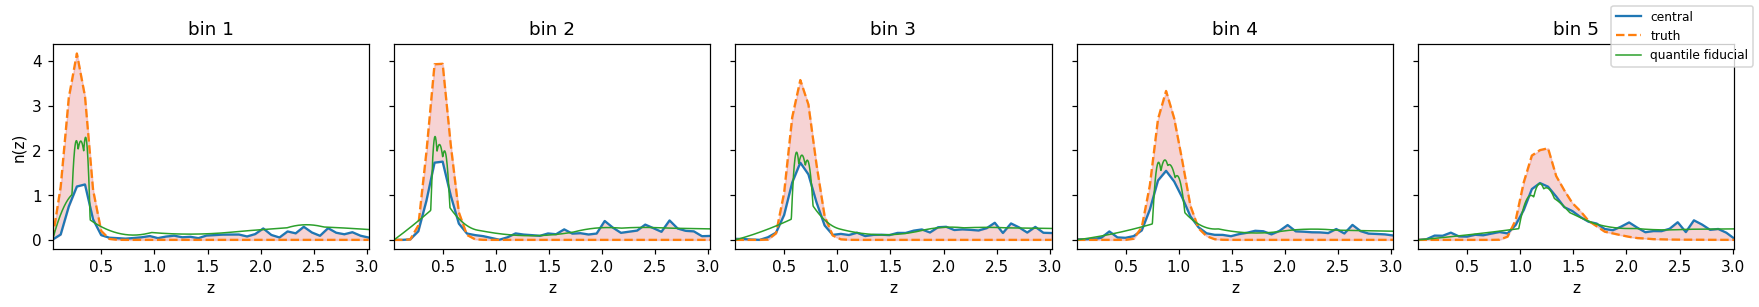

In [9]:
z_plot = np.unique(np.concatenate([np.linspace(a,b,33) for a,b in zip(z_grid[:-1],z_grid[1:])]))
fig, axes = plt.subplots(1,n_bins,figsize=(16,2.8),sharey=True,squeeze=False)
for i,ax in enumerate(axes[0]):
    ax.plot(z_grid,nz_central[i],color="C0",label="central" if i==0 else None)
    ax.plot(z_grid,nz_true[i],color="C1",ls="--",label="truth" if i==0 else None)
    nz_quant = nzq.evaluate_quantile_nz(z_plot, levels, quantile_locs[i], np.zeros(N_QPARAMS), interpolation_order=INTERPOLATION_ORDER)
    ax.plot(z_plot,nz_quant,color="C2",lw=1,label="quantile fiducial" if i==0 else None)
    ax.fill_between(z_grid,nz_central[i],nz_true[i],color="C3",alpha=0.2)
    ax.set(title=f"bin {i+1}",xlabel="z",xlim=(z_grid[0],z_grid[-1]))
axes[0,0].set_ylabel("n(z)")
fig.legend(loc="upper right",fontsize=8)
fig.tight_layout()
plt.show()

### the forecast

Same 3x2pt setup as `forecast_example.ipynb`.  The n(z) we hand it is the **central**
one -- the truth is not used here, only in the bias step below.

In [10]:
flex = FisherFlex(
    # -- the n(z) and its uncertainty ---------------------------------
    nz_source=nz_central,
    nz_realizations=samples,
    realizations_axis=1,
    z_grid=z_grid,
    photoz_prior_cov = None,
    # -- the survey ---------------------------------------------------
    neff_source=neff,                   # arcmin^-2, per tomographic bin
    fsky=0.5,
    sigma_e=0.26,                       # per-component ellipticity dispersion
    # -- the analysis -------------------------------------------------
    mode="cosmic_shear", nz_model="quantiles",
    n_quantiles=N_QUANTILES,
    quantile_interpolation_order=INTERPOLATION_ORDER
)

assert flex.n_pz_per_bin == N_QPARAMS
assert flex.pz_prior_cov.shape == (n_bins, N_QPARAMS, N_QPARAMS)
np.testing.assert_allclose(flex.quantile_locs, quantile_locs)
print("Prior de cuantiles:", flex.pz_prior_cov.shape)

flex.compute(parallel=True, save="nzdc_y1_3x2pt.npz")

forecast_params = dict(ell_max_cs=1800, ell_min_cs=300)
res = flex.forecast(**forecast_params)

s8, s8_err = res.s8()
print(f"LSST Y1 3x2pt S_8 = {s8:.4f} +/- {s8_err:.4f}")
print(f"FoM(w0,wa) = {res.fom('w_0', 'w_a'):.2f}")

Prior de cuantiles: (5, 8, 8)
Computing the fiducial data vector and covariance ...
Computing derivatives for 61 parameters (parallel) ...
Done.
Saved to nzdc_y1_3x2pt.npz
LSST Y1 3x2pt S_8 = 0.8523 +/- 0.0201
FoM(w0,wa) = 3.17


### predict the bias

`forecast_bias` forward-models the data vector twice -- once with the central n(z), once
with the truth -- and pushes the residual through Eq. (13) of the FisherA2Z paper,

$$f_\alpha = \mathbb{I}^{-1}\cdot\left(\frac{dC_\ell}{d\alpha}\cdot V\cdot(C_\ell^{\rm biased}-C_\ell)\right)$$

Everything `forecast()` accepts goes in `forecast_params`, so the bias is quoted against
exactly the forecast above -- same scale cuts, same priors.

In [11]:
bias = flex.forecast_bias(nz_truth=nz_true, forecast_params=forecast_params)

print(bias.summary(["omega_m", "sigma_8", "w_0", "w_a"]))

s8_fid, s8_shifted, ds8, ds8_sigma = bias.s8()
print(f"\nS_8: {s8_fid:.4f} -> {s8_shifted:.4f}  ({ds8:+.4f}, {ds8_sigma:+.2f} sigma)")

parameter         fiducial        bias  bias/sigma     shifted
omega_m             0.3156   -0.063866      -1.586     0.25173
sigma_8              0.831     0.01889       0.465     0.84989
w_0                     -1      0.2807       0.784     -0.7193
w_a                      0     -2.5921      -2.353     -2.5921

S_8: 0.8523 -> 0.7785  (-0.0738, -3.67 sigma)


### the bias in a 2d plane

`bias/sigma` treats each parameter on its own.  `bias_2d` marginalizes over everything
else and measures the shift against the 2x2 covariance -- the contour you actually plot.
A shift can be small in both marginal error bars and still sit outside the ellipse, if it
runs *across* the degeneracy instead of along it, so the two questions have different
answers.

In [12]:
for pair in [("omega_m", "sigma_8"), ("w_0", "w_a")]:
    print(bias.bias_2d(*pair))
    print()

bias in the (omega_m, sigma_8) plane
  omega_m           0.3156 ->     0.25173   (-1.59 sigma_1D)
  sigma_8            0.831 ->     0.84989   (+0.46 sigma_1D)
  joint: chi2 = 12.758, sqrt(chi2) = 3.57, enclosing 99.8% of the posterior
  direction: +163.5 deg;  inside 1 sigma: False;  inside 2 sigma: False

bias in the (w_0, w_a) plane
  w_0                   -1 ->     -0.7193   (+0.78 sigma_1D)
  w_a                    0 ->     -2.5921   (-2.35 sigma_1D)
  joint: chi2 = 6.162, sqrt(chi2) = 2.48, enclosing 95.4% of the posterior
  direction: -83.8 deg;  inside 1 sigma: False;  inside 2 sigma: True



In [13]:
# bias in the 2d plane

# bias in om-sigma8 plane 
print(bias.bias_2d("omega_m", "sigma_8").confidence)

# bias in wowa plane 
print(bias.bias_2d("w_0", "w_a").confidence)

0.9983028360123286
0.9540805318710193


### plot it

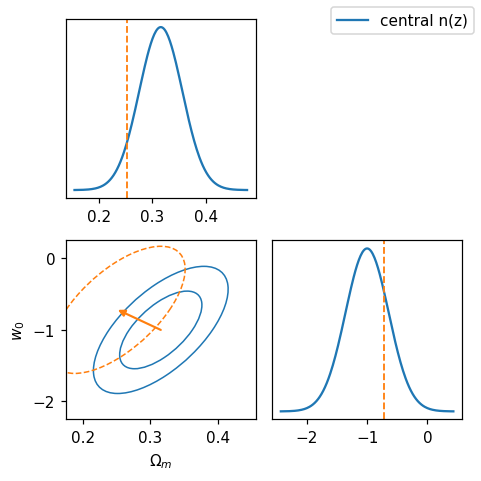

In [14]:
#params = ["omega_m", "sigma_8", "w_0", "w_a"]
params = ["omega_m", "w_0", ]


fig = res.corner(params, color="C0", label="central n(z)")
bias.corner_arrows(params, fig=fig, shifted_contour=True, color="C1")
fig.legend(loc="upper right", fontsize=10)
plt.show()

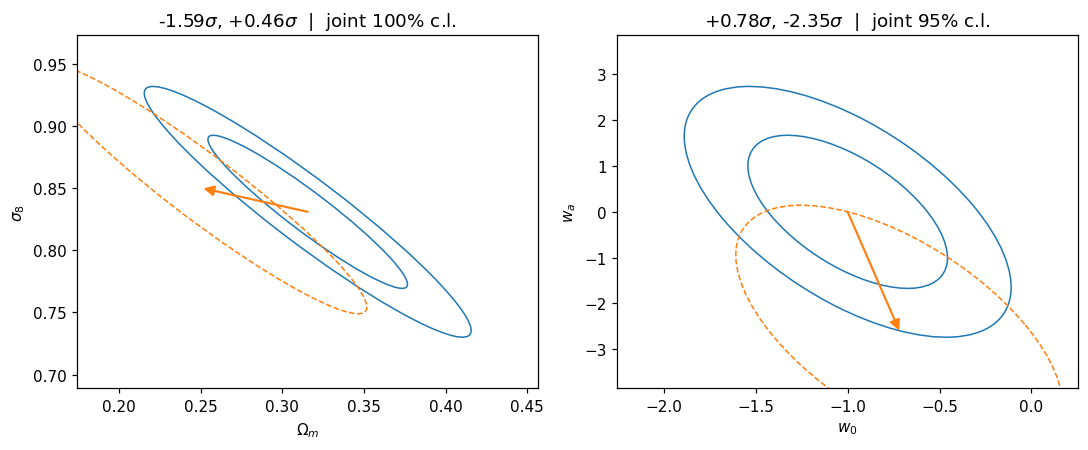

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (p1, p2) in zip(axes, [("omega_m", "sigma_8"), ("w_0", "w_a")]):
    res.contour(p1, p2, ax=ax, color="C0")
    bias.arrow(p1, p2, ax=ax, shifted_contour=True, color="C1")
    b2 = bias.bias_2d(p1, p2)
    ax.set_title(f"{bias.n_sigma(p1):+.2f}$\sigma$, {bias.n_sigma(p2):+.2f}$\sigma$"
                 f"  |  joint {b2.confidence:.0%} c.l.")
plt.tight_layout()
plt.show()